In [40]:
from II_funcs import *
import corner
import re
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
plt.rcParams['mathtext.default']='regular'

from IPython.display import FileLink
import gc
from scipy.interpolate import RectBivariateSpline
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import linregress
from astropy import units as u
import pandas as pd

theta_E_1 = np.array([np.sqrt(4 * G * .1*(2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

data=np.load('data/macro_lens_results.npz')
mag_fit=6.86
B_matrix=data['inv_jacobian_fit'][0]

In [3]:
#define image specific constants, these don't change within this file
theta_max = 2e-10 # (half) size of image
image_size=8000
N_step = image_size
#theta_max = 0.7e-10
g_params=(kappa_bulk, gamma1, gamma2)
theta_step = 2 * theta_max / image_size
vec_theta = np.linspace(-theta_max, theta_max, N_step)
arr_theta = np.asarray(np.meshgrid(vec_theta, vec_theta, indexing='xy'))
beta_min = .9e-11
rad = theta_500  
rad_mas=rad*rad_to_arcsec
g_params = (kappa_bulk, gamma1, gamma2)
sigma_C = error_C(mag=16.5, wavelength=500*1e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)


#get unlensed rotation angle, correlation points
arr_rands = jnp.array([[(300-239), (500-68)]])
star_params = (jnp.asarray([0]), D_s, D_l, D_ls, theta_max, arr_rands)
alpha_0, beta_0 = beta(g_params, star_params, arr_theta)
pad_frac = 0.1
image_0, _,_ = sparse_quasar_image(beta_0, rad, theta_max, beta_min, quasar_int_sparse)
u_full,v_full, corr_0_full=calcC_sparse(image_0, theta_step, ellipse=False)
upts_8k, vpts_8k, corr_0 = calcC_sparse(image_0, theta_step, ellipse=True)
elps_pts=jnp.asarray((vpts_8k, upts_8k)) #reversed again, as we do in the corr_C function
phi_0=-get_rot_angle(beta_0)



In [5]:
def rotate_data_pos(xpts, ypts, theta):
    "xpts, ypts are relative to 0 0 in the right bottom corner of the image. theta in radians"
    xpts=np.array(xpts)
    ypts=np.array(ypts)
    xpts=xpts-0.5
    ypts=ypts-0.5
    rs=np.sqrt(xpts**2+ypts**2)
    x2=rs*np.cos(np.arctan2(xpts, ypts)+theta)
    y2=rs*np.sin(np.arctan2(xpts, ypts)+theta)
    return x2, y2

def load_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_rad, out_mass, out_x, out_y = [], [], [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 6:
            x1, x2, rad, mass, xpos, ypos = header_vals
        elif len(header_vals) == 5:
            x1, x2 = header_vals[0], np.nan
            rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        else:
            raise ValueError(
                f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
                "Expected 5 or 6 tokens.")

        out_x1.append(x1)
        out_x2.append(x2)
        out_rad.append(rad)
        out_mass.append(mass)
        out_x.append(xpos)
        out_y.append(ypos)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.

    out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    return (out_xval,
            np.array(out_rad, dtype=float),
            np.array(out_mass, dtype=float),
            np.array(out_x, dtype=float),
            np.array(out_y, dtype=float),
            out_mat if matrix else None)
    
def load_mag_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 2:
            x1, x2 = header_vals
        if len(header_vals) == 1:
            x1 = header_vals
            x2=0
        #elif len(header_vals) == 5:
        #    x1, x2 = header_vals[0], np.nan
        #    rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        #else:
        #    raise ValueError(
        #        f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
        #        "Expected 5 or 6 tokens."
        #    )

        out_x1.append(x1)
        out_x2.append(x2)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.
    if np.array(out_x2).any!=0:
        out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    else:
        out_xval = np.column_stack([np.array(out_x1, dtype=float)])
    return (out_xval,
            out_mat if matrix else None)

def load_cents(file):
    centroids=[]
    positions=[]
    with open(file, 'r') as fh:
        lines = fh.readlines()[:]
        for i in range(len(lines)):
            #print(lines[i].split(']'))
            positions.append(np.array((float(lines[i].split(']')[0].split('[')[1].split(' ')[0]), 
                                       float(lines[i].split(']')[0].split('[')[1].split(' ')[1]))))
            J0=(np.array((float((lines[i].split(']')[1].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[1].split('[[')[1]).split(',')[1]))))
            J1=(np.array((float((lines[i].split(']')[3].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[3].split('[[')[1]).split(',')[1]))))
            J2=(np.array((float((lines[i].split(']')[5].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[5].split('[[')[1]).split(',')[1]))))
            J3=(np.array((float((lines[i].split(']')[7].split('[[')[1]).split(',')[0]), 
                                           float((lines[i].split(']')[7].split('[[')[1]).split(',')[1]))))

            J_cent=np.vstack([J0, J1, J2, J3]).T
            centroids.append(J_cent)

    return (np.array(positions), np.array(centroids))
    

def get_combo_cov(fisher_mag, cov_II, theta_step):
    #fisher_mag = jnp.linalg.inv(cov_mag.reshape(4,4))
    fisher_II = jnp.linalg.inv(cov_II.reshape(4,4))
    fisher_tot=fisher_mag+fisher_II
    cov_tot, uncertainties_tot=parameter_uncertainties(fisher_tot, theta_step, printout=False)
    return cov_tot, uncertainties_tot


def load_chi2s(file, skip_lines=0):
    """
    get chi2s from file
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)
    out_chis = []
    for line in lines:
        header_tokens = token_re.findall(line)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")
        if len(header_tokens) == 3:
            x1, x2, chi = header_tokens        
        out_chis.append(chi)
    return np.array(out_chis, dtype=float)

def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Inputs
        v_rest: velocity of the star in the lens plane in the same units at lens_dist/unit time
        redshift: redshift of lens (star)
        lens_dist: angular diameter distance to lens
        B_matrix: macrolensing matrix, inv_jacobian_fit
    Returns the lensed proper motion of the star in radians 
    """
    mu_rest = v_rest /(1 + redshift) * (1 / lens_dist) 
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")
    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    """
    if not np.all(inside):
        first_out = np.argmax(~inside)   # first False
        # truncate arrays
        times = times[:first_out]
        theta_x = theta_x[:first_out]
        theta_y = theta_y[:first_out]
        pix_x = pix_x[:first_out]
        pix_y = pix_y[:first_out]
    """
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


Load in the data over the position grids for both masses

In [6]:
position_01_mag, fish_01_mag = load_mag_file('m01_72tE_mag.txt')#, nval_x=2)
position_01, rad_01, mass_01, xpos_01, ypos_01, cov_01 = load_file('m01_72tE_II.txt')#, nval_x=3)

cov_combo_01 = []
rad_01_combo = []
mass_01_combo = []
posx_01_combo = []
posy_01_combo = []

for i in range(len(fish_01_mag)):
    combo_cov, sigma_combo=get_combo_cov(fish_01_mag[i], cov_01[i], theta_step)
    cov_combo_01.append(combo_cov)
    rad_01_combo.append(sigma_combo[0])
    mass_01_combo.append(sigma_combo[1])
    posx_01_combo.append(sigma_combo[2])
    posy_01_combo.append(sigma_combo[3])

rad_01_combo=np.array(rad_01_combo)#/(theta_500*rad_to_arcsec)
mass_01_combo=np.array(mass_01_combo)
posx_01_combo=np.array(posx_01_combo)
posy_01_combo=np.array(posy_01_combo)

position_01_rad=position_01/image_size#*theta_step
angle_rot=(-phi_0+np.pi/2)
x_rot, y_rot = rotate_data_pos(position_01_rad.T[0], position_01_rad.T[1], angle_rot)
positions_rot = np.stack([(-np.abs(x_rot)).flatten(), (np.abs(y_rot)).flatten()], axis=1) * theta_step * image_size
rotated_img=rotate(np.asarray(image_0.todense()),angle_rot*(360/(2*np.pi)))


In [7]:
chis_01_mag = load_chi2s('m01_72tE_chi2_mag.txt')#, nval_x=2)
chis_01_II = load_chi2s('m01_72tE_chi2_II.txt')#, nval_x=2)
chi_combo_01=chis_01_II+chis_01_mag

pos_cent, centroids= load_cents('m01_72tE_cent.txt') #centroids is a misnomer, its the jacobian of the centroids
centroids=centroids.reshape(10,10,2,4)
Sigma_cent= np.einsum('...ia,...ab,...jb->...ij',  centroids*rad_to_arcsec, 
                      np.array(cov_combo_01).reshape(10,10,4,4), centroids*rad_to_arcsec)

sigma_x_tot = np.sqrt(Sigma_cent[:,:,0, 0])#*rad_to_arcsec
sigma_y_tot = np.sqrt(np.abs(Sigma_cent[:,:,1, 1]))#*rad_to_arcsec
cent_pres=np.sqrt(sigma_y_tot**2+sigma_x_tot**2)


In [35]:
#define some constants for vel
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

# define the motion of a star in one year, for plotting later
dist_x = get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), B_matrix, z_l, D_l)
mu_x=np.sqrt(dist_x[0]**2+dist_x[1]**2)*365*24*3600*rad_to_arcsec

### Corner plots

Code to generate corner plots similar to those in the paper

In [11]:
from matplotlib.patches import Ellipse

def plot_cov_ellipse(mean, cov, ax, n_sigma=1.0, **kwargs):
    """
    Plotting function to make perfect ellipses on our corner plots
    """
    if not np.all(np.isfinite(cov)):
        return

    vals, vecs = np.linalg.eigh(cov)

    # must be strictly positive
    if np.any(vals <= 0):
        return

    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    theta = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    width = 2 * n_sigma * np.sqrt(vals[0])
    height = 2 * n_sigma * np.sqrt(vals[1])

    if not np.isfinite(width) or not np.isfinite(height):
        return

    ell = Ellipse(xy=mean,width=width,height=height,angle=theta,fill=False,**kwargs)
    ax.add_patch(ell)

def gaussian_1d(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma)**2) / (np.sqrt(2*np.pi) * sigma)


/mnt/home/amoran/lensing/Figures/corner01_res.pdf

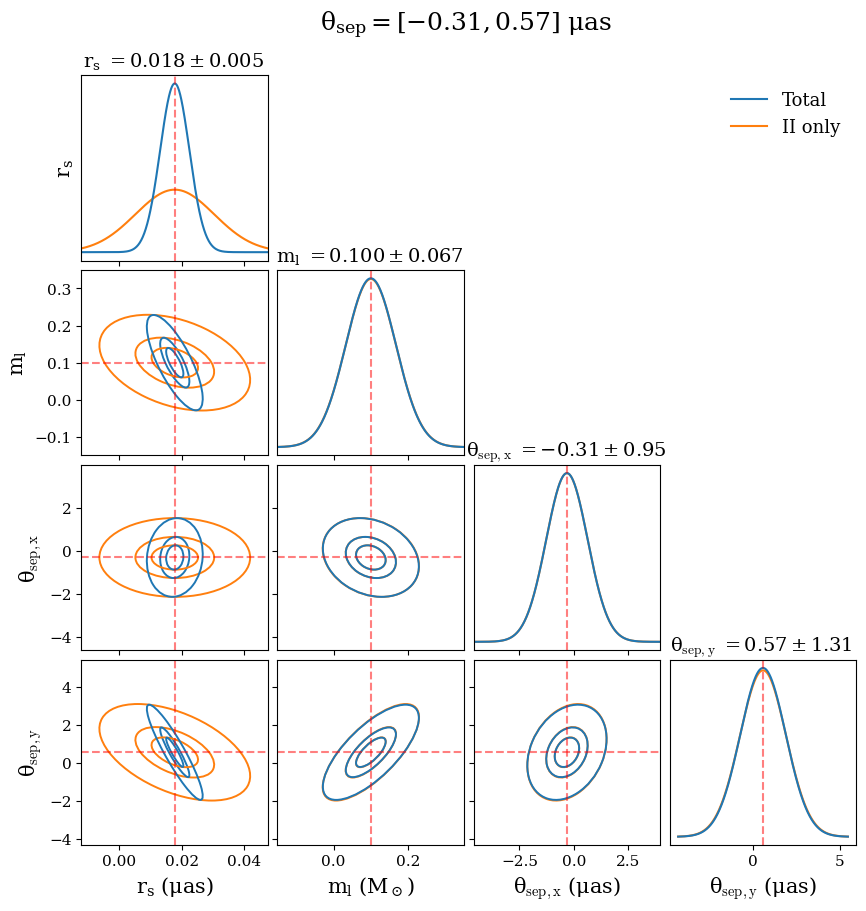

In [30]:
idx=10
pos_x_corner=(position_01[idx][0]-4000)*theta_step
pos_y_corner=(position_01[idx][1]-4000)*theta_step
mass_01_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.1, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, .25, 4.3, 4.9] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_01[idx] 
cov2 = cov_01[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

plt.text(-25, 1.45, r'$\theta_{{sep}} = [-0.31,  0.57]\ \mu$as', fontsize=18);
#plt.show()

#plt.savefig('../Figures/corner01_res.pdf', bbox_inches='tight')
#FileLink('../Figures/corner01_res.pdf')

/mnt/home/amoran/lensing/Figures/corner01_unres.pdf

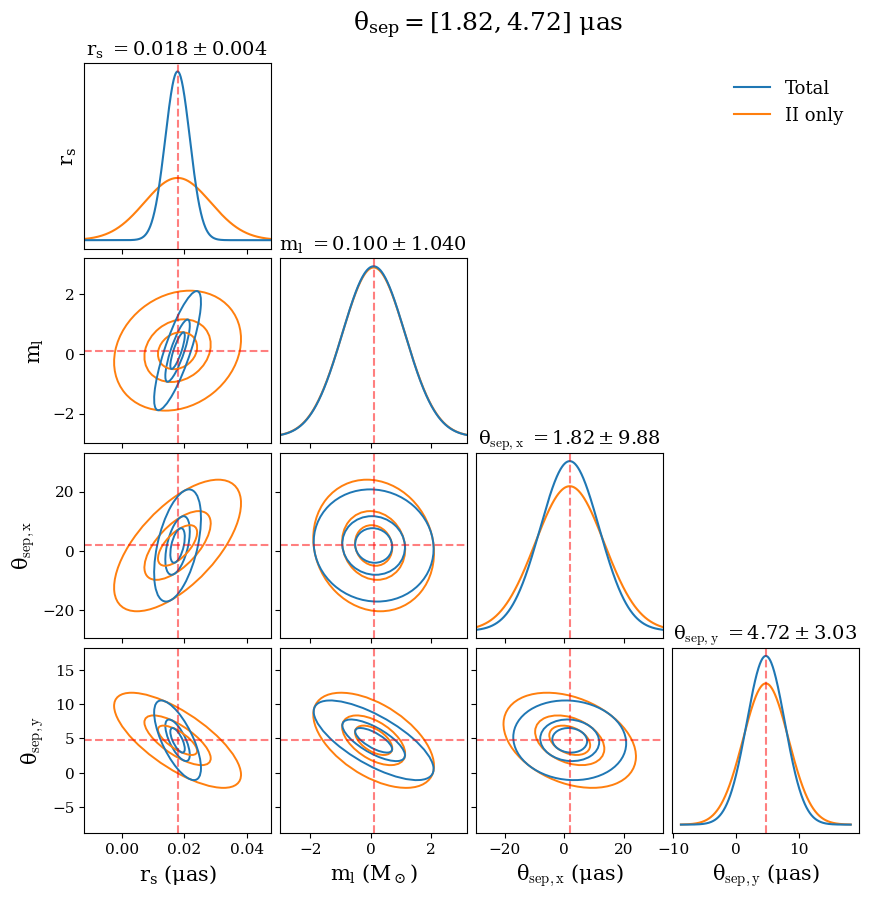

In [78]:
idx=56
pos_x_corner=(position_01[idx][0]-4000)*theta_step
pos_y_corner=(position_01[idx][1]-4000)*theta_step
mass_01_combo[idx]

titles = [r"$r_s\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_s$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.1, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, 3.1, 31.3, 13.5] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_01[idx] 
cov2 = cov_01[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

plt.text(-61, .62, r'$\theta_{{sep}} = [1.82,  4.72]\ \mu$as', fontsize=18);
#plt.show()

#plt.savefig('../Figures/corner01_unres.pdf', bbox_inches='tight')
#FileLink('../Figures/corner01_unres.pdf')

In [13]:
idx=13
pos_x_corner=(position_01[idx][0]-4000)*theta_step
pos_y_corner=(position_01[idx][1]-4000)*theta_step
mass_01_combo[idx] # old plot no longer used

np.float64(0.11398355663616008)

## Functions for generating interpolated quantities

In [22]:
def one_quad_to_full(quad_arr, n):
    """
    Reflect a quadrants worth of data over the x and y axes to get the grid in all four
    """
    arr_quadrant = quad_arr.reshape(n, n)  # this is for x<0, y<0
    
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    
    return np.concatenate((right[:-1, :], left), axis=0)
    
def matrix_to_full(quad_arr, n):
    arr_quadrant = quad_arr.reshape(n, n, 4, 4)  # this is for x<0, y<0
    
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    
    return np.concatenate((right[:-1, :], left), axis=0)

def Jac_to_full(quad_arr, n):
    # quad_arr shape: (n, n, 2, 4)
    arr = quad_arr.reshape(n, n, 2, 4)

    y_reflect  = np.flipud(arr)
    x_reflect  = np.fliplr(arr)
    xy_reflect = np.flipud(np.fliplr(arr))

    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left  = np.concatenate((np.fliplr(arr), np.fliplr(x_reflect)[:, 1:]), axis=1)

    full = np.concatenate((right[:-1, :], left), axis=0)

    return full


### Interpolate errors

In [23]:
n = int(np.sqrt(len(x_rot)))

# build grid of points rotated by phi_0
x_grid = np.unique(positions_rot[:, 0].round(decimals=18))#*theta_step * image_size
x_grid = np.concat((x_grid, (-x_grid[len(x_grid)-2::-1])))
y_grid = np.unique(positions_rot[:, 1].round(decimals=15))#*theta_step * image_size
y_grid = np.concat((-y_grid[::-1], (y_grid[1:])))

rad_grid  = rad_01_combo.reshape(n, n)
mass_grid = mass_01_combo.reshape(n, n)
xpos_grid = posx_01_combo.reshape(n, n)
ypos_grid = posy_01_combo.reshape(n, n)


In [24]:
rad_grid  = one_quad_to_full(rad_01_combo, n)
mass_grid = one_quad_to_full(mass_01_combo, n)
xpos_grid = one_quad_to_full(posx_01_combo, n)
ypos_grid = one_quad_to_full(posy_01_combo, n)


In [25]:
# Build interpolators
rad_spline  = RegularGridInterpolator([x_grid, y_grid], rad_grid, method='linear')
mass_spline = RegularGridInterpolator([x_grid, y_grid], mass_grid, method='linear')
xpos_spline = RegularGridInterpolator([x_grid, y_grid], xpos_grid, method='linear') #takes position in radians, returns in mas
ypos_spline = RegularGridInterpolator([x_grid, y_grid], ypos_grid, method='linear')

In [26]:
# build fine grid to test these functions
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')


In [27]:
#evlulate on the dense grids for plotting
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
rad_interp = rad_spline(points).reshape(X_fine.shape)
mass_interp = mass_spline(points).reshape(X_fine.shape)
xpos_interp = xpos_spline(points).reshape(X_fine.shape)
ypos_interp = ypos_spline(points).reshape(X_fine.shape)

### Interpolate fisher matricies for m=0.1

In [29]:
# do this element wise, reshape back to a 4x4 grid at each point in the n x n grid
f_combo_01=[]
for i in range(len(cov_combo_01)):
    f_combo_01.append(np.linalg.inv(cov_combo_01[i]))
f_combo_01=np.array(f_combo_01)
f_combo_01 = f_combo_01.reshape(n, n, 4, 4)
f_combo_01  = matrix_to_full(f_combo_01, n)

In [30]:
#interpolate each element of the fisher matricies separately
interpolators = [[None for j in range(4)] for i in range(4)]

for i in range(4):
    for j in range(4):
        # Linear interpolation; 'bounds_error=False' allows extrapolation if needed
        interpolators[i][j] = RegularGridInterpolator(
            (x_grid, y_grid),
            f_combo_01[:, :, i, j], bounds_error=False, method='linear', fill_value=np.nan)
#build the function which will call each interpolator and put into a matrix
def fisher_interp_linear(pos):
    x, y = pos
    M = np.zeros((4, 4))
    for i in range(4):
        for j in range(4):
            M[i, j] = interpolators[i][j]([x, y])
    # enforce symmetry
    M = 0.5 * (M + M.T)
    return M

### Interpolate chi^2, J_cent

Same process as above, interpolate everything element wise if necessary, and build into a function. 

In [31]:
chi_grid  = one_quad_to_full(chi_combo_01, n)

fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)

chi_spline  = RegularGridInterpolator([x_grid, y_grid], chi_grid, bounds_error=False, method='linear', fill_value=np.nan)
chi_interp  = chi_spline(points).reshape(X_fine.shape)

In [32]:
chi_grid_II  = one_quad_to_full(chis_01_II, n)
chi_spline_II  = RegularGridInterpolator([x_grid, y_grid], chi_grid_II, bounds_error=False, method='linear', fill_value=np.nan)

chi_grid_mag  = one_quad_to_full(chis_01_mag, n)
chi_spline_mag  = RegularGridInterpolator([x_grid, y_grid], chi_grid_mag, bounds_error=False, method='linear', fill_value=np.nan)

In [33]:

centroids=centroids.reshape(n,n,2,4)
Jcent_grid  = Jac_to_full(centroids, n)

interpolators_cent=[[None for i in range(4)] for a in range(2)]

for a in range(2):        # centroid x/y
    for i in range(4):    # parameters
        interpolators_cent[a][i] = RegularGridInterpolator(
        (x_grid, y_grid),
        Jcent_grid[:, :, a, i], bounds_error=False, method='linear', fill_value=np.nan)

def Jcent_interp(pos):
    x, y = pos
    J = np.zeros((2, 4))
    for a in range(2):
        for i in range(4):
            J[a, i] = interpolators_cent[a][i]([x, y])
    return J

cent_pres  = one_quad_to_full(cent_pres, n)
cent_spline = RegularGridInterpolator([x_grid, y_grid], cent_pres, method='linear', fill_value=np.nan)
cent_interp = cent_spline(points).reshape(X_fine.shape)

/mnt/home/amoran/lensing/Figures/chi01.pdf

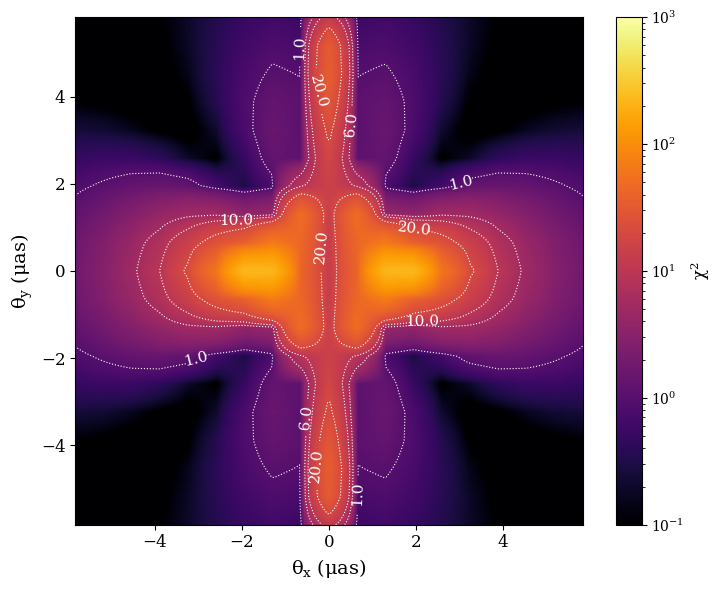

In [35]:
Z = np.flipud(chi_interp).T
X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

levels=[1, 6, 10, 20]
fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(Z, origin='lower', extent=extent, cmap='inferno', norm=matplotlib.colors.LogNorm(vmin=.1,vmax=1000),)
contours = ax.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax.clabel(contours, inline=True, fontsize=11, fmt="%.1f")

cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=.03)
cbar.set_label(r'$\chi^2$', fontsize=12)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='minor', labelsize=10)

ax.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()
#plt.savefig('../Figures/chi01.pdf', bbox_inches='tight')
#FileLink('../Figures/chi01.pdf')

### Error Plots

Plots of the interpolated errors as evaluted on a finer grid of points

We see some numerical noise but within what we would expect to see

In [34]:
orig_map=plt.cm.get_cmap('cividis')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

/tmp/ipykernel_1790287/603653901.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=plt.cm.get_cmap('cividis')


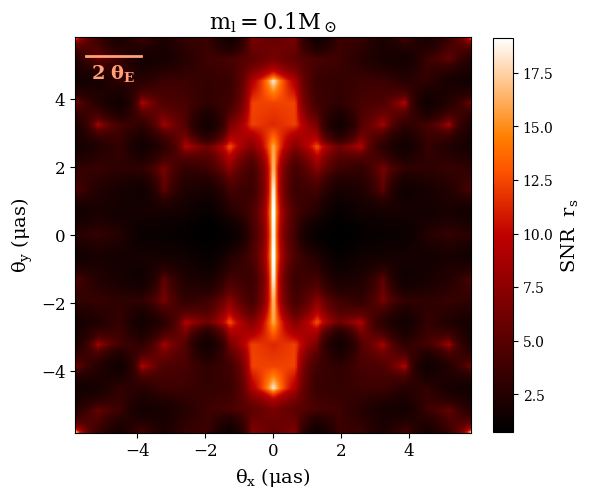

In [36]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    
extent2 = [-theta_max, theta_max, -theta_max, theta_max]    #left right bottom top 

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = rad_mas/np.flipud(rad_interp).T

levels=[.1, .6]
im=ax1.imshow(Z, origin='lower', extent=extent, cmap='gist_heat')
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
cbar.set_label(r'SNR $ \ r_s$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

#scale thing
scale_length = 2*theta_E_1*rad_to_arcsec    

# pick a position for the bar 
x_start = np.min(fine_grid_x) - 3.4 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='lightsalmon', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='lightsalmon', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white')


ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
plt.title(r'$m_l=0.1M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)


ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

#plt.savefig('../Figures/chi01.pdf', bbox_inches='tight')
#FileLink('../Figures/chi01.pdf')

/mnt/home/amoran/lensing/Figures/mass_01.pdf

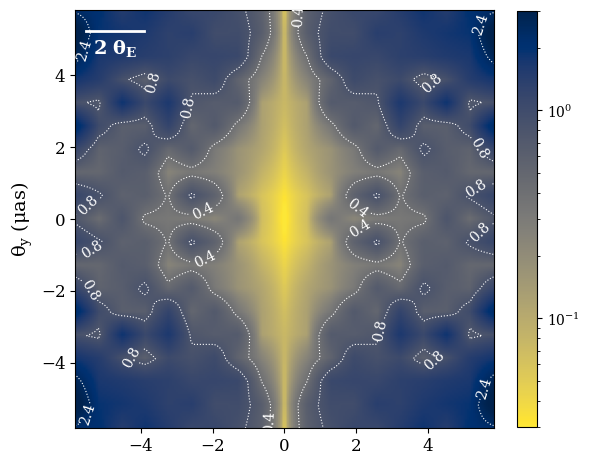

In [66]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    
extent2 = [-theta_max, theta_max, -theta_max, theta_max]    #left right bottom top 

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(mass_interp).T

levels=[ .4, .8, 2.4]
im=ax1.imshow(np.flipud(mass_interp).T, origin='lower', cmap=reversed_map, norm=matplotlib.colors.LogNorm(vmin=3e-2,vmax=3), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [m_l]\  (M_\odot)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

scale_length = 2*theta_E_1*rad_to_arcsec    

# pick a position for the bar 
x_start = np.min(fine_grid_x) - 3.4 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white')

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)


#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()


#plt.savefig('../Figures/mass_01.pdf', bbox_inches='tight')
#FileLink('../Figures/mass_01.pdf')

/mnt/home/amoran/lensing/Figures/pos_01.pdf

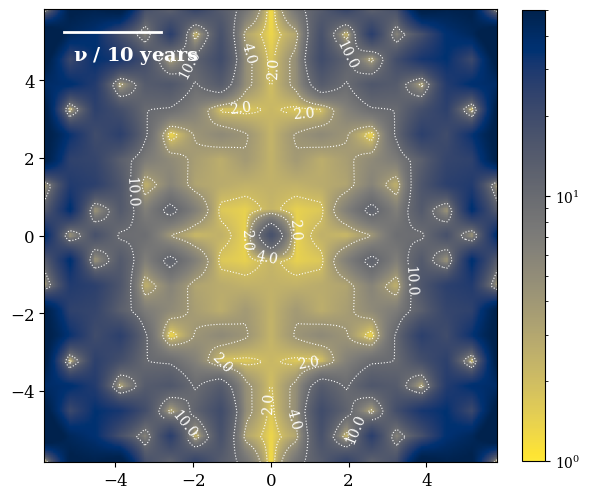

In [64]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.sqrt(np.flipud(xpos_interp).T**2+np.flipud(xpos_interp).T**2)
levels=[2, 4, 10]
im=ax1.imshow(Z, origin='lower',cmap=reversed_map,norm=matplotlib.colors.LogNorm(vmin=1,vmax=50), extent=extent)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
#cbar.set_label(r'$ \sigma \ [\theta_{\text{sep}}] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

scale_length=mu_x*10
x_start = np.min(fine_grid_x) - 2.12 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text(x_start+1.85, y_pos * .83, r"$\nu \ / $ 10 years", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')#, backgroundcolor='white') # this is lensed along the x axis!!


ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

#plt.savefig('../Figures/pos_01.pdf', bbox_inches='tight')
#FileLink('../Figures/pos_01.pdf')

/mnt/home/amoran/lensing/Figures/thetac_01.pdf

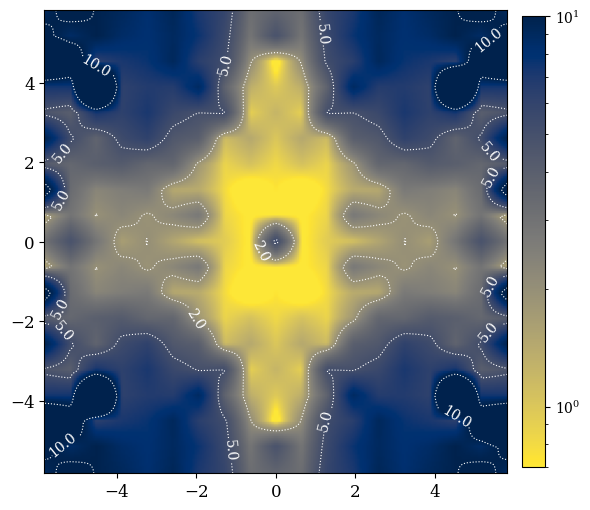

In [65]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6, 8))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec    

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(cent_interp).T
levels=[ 2, 5, 10]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent,norm=matplotlib.colors.LogNorm(vmin=.7,vmax=10))#,  vmax=68, vmin=1)
cbar = plt.colorbar(im, ax=ax1, fraction=0.045, pad=.03)
#cbar.set_label(r'$ \sigma \ [|\theta_{\text{c}}|] \ (\mu as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
#plt.title(r'$m_l=0.8M_\odot$', fontsize=16)
#ax1.set_xlim(-1.4e-11, .1e-11)
#ax1.set_ylim(-.1e-11, 1.4e-11)

#ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
#ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()
#plt.savefig('../Figures/thetac_01.pdf', bbox_inches='tight')
#FileLink('../Figures/thetac_01.pdf')

### Simulating moving stars

In [27]:
def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Inputs
        v_rest: velocity of the star in the lens plane in the same units at lens_dist/unit time
        redshift: redshift of lens (star)
        lens_dist: angular diameter distance to lens
        B_matrix: macrolensing matrix, inv_jacobian_fit
    Returns the lensed proper motion of the star in radians 
    """
    mu_rest = v_rest /(1 + redshift) * (1 / lens_dist) 
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


In [37]:
def plot_star_trajectory(traj, theta_max, show_start_end=True, ax=None):
    """
    Plot a single star trajectory
    
    show_start_end : bool, optional
        Mark starting and ending positions with scatter points
    ax : matplotlib.axes.Axes, optional
        Axes to plot on. If None, creates a new figure.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    theta_x, theta_y = traj["positions_rad"].T

    # Plot trajectory
    ls = '-'
    ax.plot(theta_x, theta_y, ls, color='C0', marker='.', linewidth=1.5)
    if show_start_end:
        ax.scatter(theta_x[0], theta_y[0], c='green', s=40, label='Start', zorder=3)
        ax.scatter(theta_x[-1], theta_y[-1], c='red', s=40, label='End', zorder=3)

    ax.set_xlim(-theta_max, theta_max)
    ax.set_ylim(-theta_max, theta_max)
    ax.tick_params(axis='both', which='major', labelsize=12)

    ax.grid(True, linestyle='--', alpha=0.3)

    ax.set_xlabel(r'$\theta_x [\text{rad}]$', fontsize=15)
    ax.set_ylabel(r'$\theta_y [\text{rad}]$', fontsize=15)
    ax.set_aspect('equal', 'box')
    ax.legend(fontsize=14)
    return ax

def f_alpha_to_f_Theta(f_alpha, times):
    """
    Convert f_alpha matrices (time-dependent) into a symmetric 6x6 f_Theta matrix
    inputs:
        f_alpha, shape (len(times), 4, 4)
        times: with t=0 at closest approach
    Returns f_theta, of shape 6,6
    """
    f_Theta = np.zeros((6, 6))

    for time, f_a in zip(times, f_alpha):
        # Upper 4x4 block
        f_Theta[:4, :4] += f_a

        # 5th row
        f_Theta[4, :4] += time * f_a[2, :]
        f_Theta[:4, 4] = f_Theta[4, :4]  # symmetry
        f_Theta[4, 4] += (time ** 2) * f_a[2, 2]

        # 6th row 
        f_Theta[5, :4] += time * f_a[3, :]
        f_Theta[:4, 5] = f_Theta[5, :4]  
        f_Theta[5, 4] += (time ** 2) * f_a[2, 3]
        f_Theta[4, 5] = f_Theta[5, 4]    
        f_Theta[5, 5] += (time ** 2) * f_a[3, 3]

    return f_Theta

<Axes: xlabel='$\\theta_x [\\text{rad}]$', ylabel='$\\theta_y [\\text{rad}]$'>

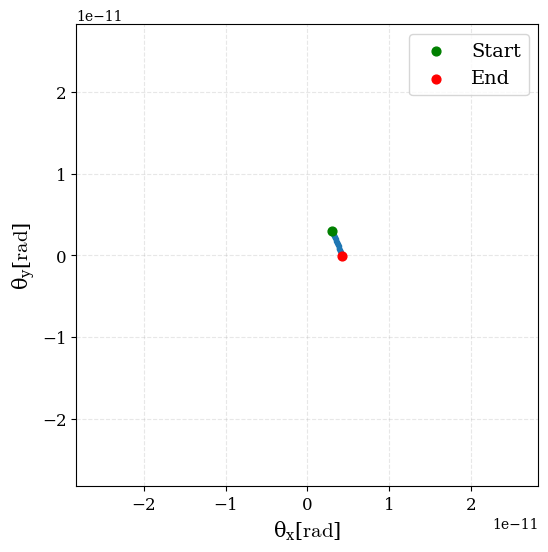

In [38]:
# one test to make sure this is working, plot 
test_traj=sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, 
                        np.max(x_grid), 8000, z_l, D_l, B_matrix, theta_E_1[0])
plot_star_trajectory(test_traj, np.max(x_grid))

In [28]:
# build up the fisher matricies for each point, built the uncertainties in alpha space
positions_traj=test_traj['positions_rad']
fisher_alpha=[]
uncert_alphas=[]
for position_i in positions_traj:
    fisher_alpha.append(fisher_interp_linear(position_i))
    uncert_alphas.append(parameter_uncertainties(fisher_alpha[-1], theta_step, printout=False)[1])
uncert_alphas=np.array(uncert_alphas)

/tmp/ipykernel_1655361/3414513389.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])


In [29]:
# go to theta space to get full derived information 
f_Theta = f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24))
cov_Theta, uncert_Theta = parameter_uncertainties(f_Theta, theta_step, printout=False, numstars=1)

### Now for many stars to get some averages

In [39]:
def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    Given the 6x6 Theta covariance, return the 1σ uncertainties
    on *unlensed* (physical) vx, vy in km/s.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 lensed angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))   
    return cov_v_cm, cov_v_kms, sigma_v_kms


def average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, chi_spline,
                  dt_days=182.0, max_time_days= 5 * 365.0, n_its=100, fisher_spline=fisher_interp_linear):
    """
    Simulate random trajectories of a lensing system and compute average uncertainties and covariances for 
    trajectory parameters and centroid positions.

    Inputs:
    bulk_vel: float, lensing galaxy bulk vel in km/s
    bulk_vel_err: float, km/s
    vel_disp: float, vel dist of the stars in the lensing galaxy, km/s
    vel_disp_err: float, km/s
    theta_max: radians
    N: int, # of steps in each simulated trajectory
    redshift: float, source z
    lens_dist: float, lens distance (in same units as used in simulations)
    B_matrix: inv_jacobian of the macrolensing stuff
    dist: lens distance in cm 
    chi_spline , fisher_spline: callable default `fisher_interp_linear` for fisher_spline
    dt_days: float, optional. time step in days for trajectory simulation (default 182.0)
    max_time_days: float, optional, max total simulation time in days (default 5 years)
    n_its: int, optional, how many lenses to simulate motion for averaving    
    
    Outputs:
    cov_thetas: array: 6x6 cov matrixies for each lens trajectory
    cov_avg: average across trajectories
    uncert_thetas: array, len 6, uncertaintiy in theta space for each traj
    uncert_avg: average of that
    vels: the velocity we drew in each trajectory realization
    chi_all: array: total chi^2 values summed over each trajecotry
    retries: list of int, Number of retries needed for each trajectory to avoid NaNs in uncertainties.
    Jcents: array of 2x2 centroid covariance matricies combiend over each traj.
    """
    
    fisher_thetas=[]
    cov_thetas=[]
    uncert_thetas=[]
    vels=[]
    chi_all=[]
    retries=[]
    Jcents=[]
    for it in range(n_its):
        test_traj= sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift,
                                         lens_dist, B_matrix, dist,  dt_days=182.0, max_time_days= max_time_days)    
        positions_traj=test_traj['positions_rad']
        fisher_alpha=[]
        uncert_alphas=[]
        chi_traj=[]
        centJ_traj=[]
        vels.append(test_traj['velocity_kms'])
        for position_i in positions_traj:
            fisher_alpha.append(fisher_spline(position_i))
            uncert_alphas.append(parameter_uncertainties(fisher_alpha[-1], theta_step, printout=False)[1])
            chi_traj.append(chi_spline(position_i))
            centJ_traj.append(Jcent_interp(position_i))

            
        retry=0
        fisher_theta_traj=(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
        cov_Theta, uncert_Theta = parameter_uncertainties(fisher_theta_traj, theta_step, printout=False, numstars=1)
        while np.any(np.isnan(uncert_Theta)):
            retry += 1
            test_traj= sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift,
                                         lens_dist, B_matrix, dist,  dt_days=182.0, max_time_days= max_time_days)
            positions_traj=test_traj['positions_rad']
            fisher_alpha=[]
            uncert_alphas=[]
            chi_traj=[]
            Jcent_traj=[]
            vels.append(test_traj['velocity_kms'])
            for position_i in positions_traj:
                fisher_alpha.append(fisher_spline(position_i))
                uncert_alphas.append(parameter_uncertainties(fisher_alpha[-1], theta_step, printout=False)[1])
                chi_traj.append(chi_spline(position_i))
                Jcent_traj.append(Jcent_interp(position_i))
            fisher_theta_traj=(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
            cov_Theta, uncert_Theta = parameter_uncertainties(fisher_theta_traj, theta_step, printout=False, numstars=1)
        
        retries.append(retry)  
        centJ_traj=np.array(centJ_traj)
        centJ_traj = np.array([j.reshape(2,4) for j in centJ_traj])
        uncert_alphas=np.array(uncert_alphas)
        chi_all.append(np.sum(chi_traj))
        centroid_cov_traj = []

        for t in range(len(positions_traj)):
            J = centJ_traj[t]          # shape (2,4)
            C_alpha = np.linalg.inv(fisher_alpha[t])  # shape (4,4)
            C_cent = J @ C_alpha @ J.T    # shape (2,2)
            centroid_cov_traj.append(C_cent)
        
        centroid_cov_traj = np.array(centroid_cov_traj)
        Cinv_tot = np.zeros((2, 2))
        
        for C in centroid_cov_traj:
            Cinv_tot += np.linalg.inv(C)
        
        C_cent_tot = np.linalg.inv(Cinv_tot)
        Jcents.append(C_cent_tot)
        fisher_thetas.append(f_alpha_to_f_Theta(fisher_alpha, test_traj['times_days']*(3600*24)))
        cov_v_cm, cov_v_kms, sigma_v_kms = unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist)
        cov_Theta, uncert_Theta = parameter_uncertainties(fisher_thetas[-1], theta_step, printout=False, numstars=1)
        cov_thetas.append(cov_Theta)
        uncert_unlensed = np.array(uncert_Theta.copy())
        
        # replace last two entries 
        _,_, sigma_v_kms = unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist)
        uncert_unlensed[4] = sigma_v_kms[0]*4.848136811e-12 # correct for mas to radians
        uncert_unlensed[5] = sigma_v_kms[1]*4.848136811e-12
        
        # store full 6-element uncertainty vector
        uncert_thetas.append(uncert_unlensed)
    cov_thetas=np.array(cov_thetas)
    Jcents=np.array(Jcents)
    chi_all=np.array(chi_all)#.reshape(len(chi_all))    
    cov_avg=np.mean(cov_thetas, axis=0)
    uncert_thetas=np.array(uncert_thetas)
    uncert_avg=np.sum(uncert_thetas, axis=0)/n_its
    vels=np.array(vels)
    return cov_thetas, cov_avg, uncert_thetas, uncert_avg, vels, chi_all, retries,  Jcents

In [61]:
# test this out before looping it
cov_theta_all, cov_avg, uncert_theta_all, uncert_avg, vels, chi_traj, n_retry=average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, 
                                    np.max(x_grid), 8000, z_l, D_l, B_matrix, 5*theta_E_1[0], chi_spline, fisher_spline=fisher_interp_linear)

/tmp/ipykernel_3974915/3414513389.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])


### Uncertainties as a function of min impact parameter

In [70]:
# generate impact paramter array, use a 0.8 solar mass star so we can compare between stars how we do
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

impact_params = np.linspace(.3*theta_E_8[0], 5.9*theta_E_8[0], 40)
impact_params=impact_params[0:15] # no need to do all of them because the very distant points we have no hope
# of resolving for a lens this low mass (we can resolve them for the higher mass lenses)

chi_tots = []
uncert_avgs = []
n_retries = []
chi_dists = [] #for full distribution
uncert_dists = [] 
cent_all=[]
# get all the quantities! run many times for each impact parameter to average over all all possible angles of approach
for impact_param in impact_params:
    (cov_theta_all, cov_avg, uncert_theta_all, uncert_avg, vels, chi_traj_avg, n_r, cent_tot) = average_errors_traj(
                        bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, np.max(x_grid), 8000, 
                        z_l, D_l, B_matrix, impact_param, chi_spline, fisher_spline=fisher_interp_linear,
                        n_its=1000, max_time_days=2.5*365.0)

    cent_all.append(cent_tot)
    chi_tots.append(chi_traj_avg.mean())
    uncert_avgs.append(uncert_avg)
    n_retries.append(n_r)
    chi_dists.append(chi_traj_avg)
    uncert_dists.append(uncert_theta_all)

chi_tots = np.array(chi_tots)
uncert_avgs = np.array(uncert_avgs)
n_retries = np.array(n_retries)
cent_all=np.array(cent_all)
chi_dists = np.array(chi_dists, dtype=object)
uncert_dists = np.array(uncert_dists, dtype=object)

# if we already have run this, add these on
try:
    existing = np.load("avgs_01_setx.npz", allow_pickle=True) # set_x is becuase we used to let the velocity be 
    # in any direction. for stability now we've set that 

    chi_all = np.hstack([existing["chi_tots"], chi_tots])
    cent_all = np.hstack([existing["cent_all"], cent_all])
    uncert_all = np.vstack([existing["uncert_avgs"], uncert_avgs])
    impact_all =np.hstack([existing["impact_params"], impact_params])
    n_retries_all =np.hstack([existing["n_retried"], n_retries])
    chi_dists_all= np.hstack([existing["chi_dists"], chi_dists])
    uncert_dists_all = np.hstack([existing["uncert_dists"], uncert_dists])

#first run, generate new file
except FileNotFoundError:
    chi_all = chi_tots
    cent_all=cent_all
    uncert_all= uncert_avgs
    impact_all = impact_params
    n_retries_all = n_retries
    chi_dists_all= chi_dists
    uncert_dists_all = uncert_dists


np.savez("avgs_01_setx.npz", impact_params = impact_all, chi_tots= chi_all,
         cent_all=cent_all, uncert_avgs = uncert_all, n_retried = n_retries_all, 
         chi_dists= chi_dists_all, uncert_dists= uncert_dists_all,)


/tmp/ipykernel_60072/3414513389.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  M[i, j] = interpolators[i][j]([x, y])
/tmp/ipykernel_60072/1695468831.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  J[a, i] = interpolators_cent[a][i]([x, y])


In [6]:
# load it back in
data = np.load("avgs_01_setx.npz", allow_pickle=True)

impact_params_all = data["impact_params"]
chi_all= data["chi_tots"]
uncert_all = data["uncert_avgs"]
chi_dists_all = data["chi_dists"]
uncert_dists_all = data["uncert_dists"] 

uniq = np.unique(impact_params_all)
chi_mean   = np.zeros(len(uniq))
uncert_mean = np.zeros((len(uniq), uncert_all.shape[1]))

for i, u in enumerate(uniq):
    mask = impact_params_all == u
    chi_mean[i]   = chi_all[mask].mean()
    uncert_mean[i] = uncert_all[mask].mean(axis=0)

impact_params = uniq
chi_full=np.array(chi_dists_all)
uncert_full=np.array(uncert_dists_all)

In [7]:
# calcualte the percentiles for all this for plotting purposes
cent_all=data["cent_all"]
sigma_x_mean = np.mean(np.sqrt(cent_all[:,:, 0, 0]), axis=-1)
sigma_y_mean = np.mean(np.sqrt(cent_all[:,:, 1, 1]), axis=-1)
cent_mean=np.sqrt(sigma_x_mean**2+sigma_y_mean**2)

sigma_x_50 = np.nanpercentile(np.sqrt(cent_all[:,:, 0, 0]), 50, axis=-1)
sigma_y_50 = np.nanpercentile(np.sqrt(cent_all[:,:, 1, 1]), 50, axis=-1)
cent_50=np.sqrt(sigma_x_50**2+sigma_y_50**2)

sigma_x_16 = np.nanpercentile(np.sqrt(cent_all[:,:, 0, 0]), 16, axis=-1)
sigma_y_16 = np.nanpercentile(np.sqrt(cent_all[:,:, 1, 1]), 16, axis=-1)
cent_16=np.sqrt(sigma_x_16**2+sigma_y_16**2)

sigma_x_84 = np.nanpercentile(np.sqrt(cent_all[:,:, 0, 0]), 84, axis=-1)
sigma_y_84 = np.nanpercentile(np.sqrt(cent_all[:,:, 1, 1]), 84, axis=-1)
cent_84=np.sqrt(sigma_x_84**2+sigma_y_84**2)

In [8]:
#check that all of these are in the area under chi^2=10, and they are!
n_retrys=data['n_retried']
cut=0
for i in range(len(n_retrys)):
    tries=np.sum(n_retrys[i])
    if tries>0:
        print("pos", np.array(impact_params/theta_E_8[0])[i], ':', tries)
    if np.percentile(chi_full, 50, axis=1)[i]<10 and cut==0:
        print('cutoff is ', np.array(impact_params/theta_E_8[0])[i])
        print('limit x axis to ', np.array(impact_params/theta_E_8[0])[i-1])
        xlim=np.array(impact_params/theta_E_8[0])[i-1]
        cut=10

cutoff is  1.8794871794871797
limit x axis to  1.7358974358974364


In [16]:
chi_dists_all.shape

(15, 10300)

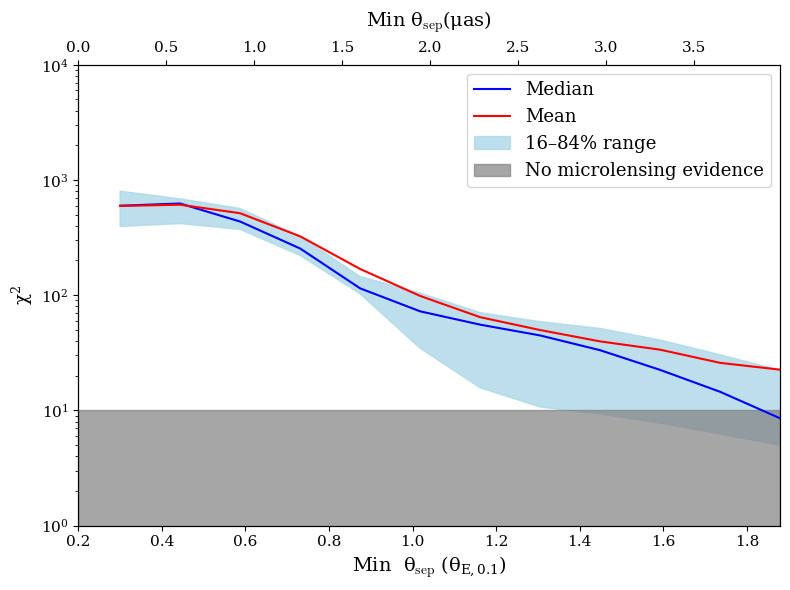

In [79]:
p16= np.array(np.percentile(chi_full, 16, axis=1), dtype=float)
p84 = np.array(np.percentile(chi_full, 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, np.percentile(chi_full, 50, axis=1), color='blue', label='Median')
ax.plot(impact_params / theta_E_8, chi_mean, label='Mean', color='red')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.axhspan(0,10, label='No microlensing evidence', alpha=.7, color='gray')
ax.set_ylabel(r'$\chi^2$', fontsize=13)
ax.set_xlabel(r'Min  $\theta_{\text{sep}}$ ($\theta_{E, 0.1}$)', fontsize=14)
ax.set_yscale('log')
ax.set_xlim(.2, 1.879)
ax.set_ylim(1, 1e4)
ax.legend(fontsize=13)
fig.tight_layout() # 5 years

#### Uncertainties 

In [17]:
# load in the averages
uncert_rads_avg =np.array(np.percentile(uncert_full[:,:,0], 50, axis=1))
uncert_mass_avg =np.array(np.percentile(uncert_full[:,:,1], 50, axis=1))
uncert_xpos_avg =np.array(np.percentile(uncert_full[:,:,2], 50, axis=1))
uncert_ypos_avg =np.array(np.percentile(uncert_full[:,:,3], 50, axis=1))
uncert_xvel_avg =np.array(np.percentile(uncert_full[:,:,4], 50, axis=1))
uncert_yvel_avg =np.array(np.percentile(uncert_full[:,:,5], 50, axis=1))

In [20]:
#build this for veiwing the data (very optional)
df=pd.DataFrame((np.array((impact_params/theta_E_8[0], uncert_rads_avg, uncert_mass_avg, uncert_xpos_avg, 
                           uncert_ypos_avg, uncert_xvel_avg, uncert_yvel_avg, cent_50*rad_to_arcsec)).T))

,0,1,2,3,4,5,6,7
0,0.3,0.000337,0.010349,0.191338,0.114099,146.386544,207.156446,0.095454
1,0.44359,0.000325,0.010175,0.162418,0.086947,161.813114,215.335545,0.068645
2,0.587179,0.000331,0.010266,0.166195,0.086904,198.206531,263.450259,0.060365
3,0.730769,0.000327,0.0107,0.179948,0.087505,204.817783,266.410768,0.059281
4,0.874359,0.000352,0.011357,0.193819,0.098029,203.83673,270.948395,0.085952
5,1.017949,0.000354,0.013206,0.216881,0.130458,228.257834,335.205956,0.105557
6,1.161538,0.000323,0.017834,0.240141,0.197864,284.451733,502.754554,0.130892
7,1.305128,0.000281,0.024559,0.266654,0.287239,399.555495,749.445446,0.146407
8,1.448718,0.000268,0.031452,0.289742,0.232056,383.765679,615.06091,0.206287
9,1.592308,0.000291,0.042936,0.318896,0.21687,405.047605,634.574571,0.287388


In [ ]:
p16 = cent_16*rad_to_arcsec
p84= cent_84*rad_to_arcsec

fig,ax = plt.subplots(figsize=(8,6))
ylim=.0015
xlim=5.5
ax.plot(impact_params / theta_E_8, cent_mean*rad_to_arcsec, label='Mean', color='red')
ax.plot(impact_params / theta_E_8, cent_50*rad_to_arcsec, color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')


ticks_top=np.linspace(theta_E_8[0]*rad_to_arcsec, 8*theta_E_8[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0, xlim*theta_E_8[0]*rad_to_arcsec)

#ax_right = ax.twinx() # for top axis
#ax_right.spines["top"].set_position(("axes", 1))
#ax_right.set_ylabel(r'$\sigma_{rs}$ ($r_s$)',  fontsize=14, labelpad=10)
#ax_right.set_ylim(0,ylim/rad_mas)

#ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma \ |\mathbf{\theta_{c}}|$ ($\mu$as)",  fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)

ax.legend(fontsize=13)
fig.tight_layout()

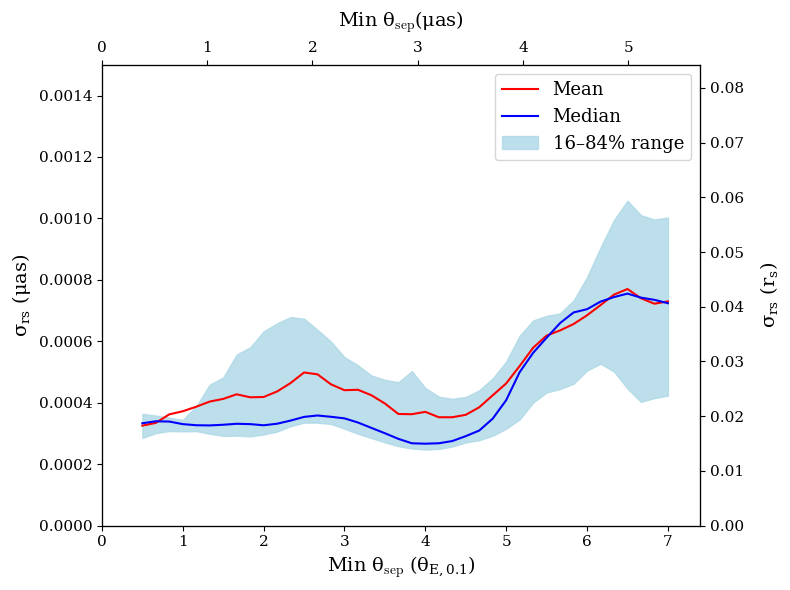

In [62]:
p16 = np.array(np.percentile(uncert_full[:,:,0], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,0], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ylim=.0015
ax.plot(impact_params / theta_E_8, uncert_rads_avg, label='Mean', color='red')
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,0], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ticks_top=np.linspace(theta_E_8[0]*rad_to_arcsec, 8*theta_E_8[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
ax_right.set_ylabel(r'$\sigma_{rs}$ ($r_s$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/rad_mas)

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma_{rs}$ ($\mu$as)",  fontsize=14)
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)

ax.legend(fontsize=13)
fig.tight_layout()

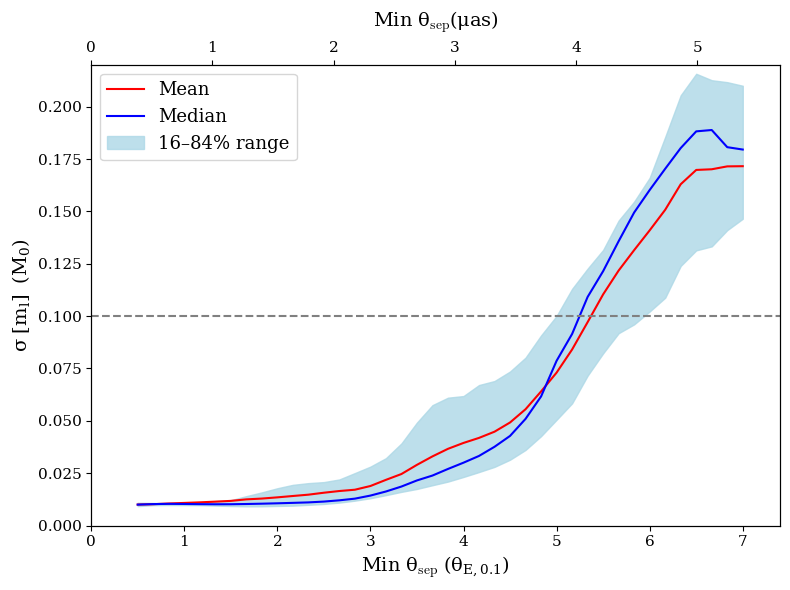

In [63]:
p16 = np.array(np.percentile(uncert_full[:,:,1], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,1], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ax.plot(impact_params / theta_E_8, uncert_mass_avg,  label='Mean', color='red')
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,1], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)
ax.axhline(0.1, linestyle='dashed', color='gray')


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [m_l]\ \ (M_0)$", fontsize=14)
ax.set_xlim(0,xlim)
ax.set_ylim(0, .22)
ax.legend(fontsize=13)
fig.tight_layout()

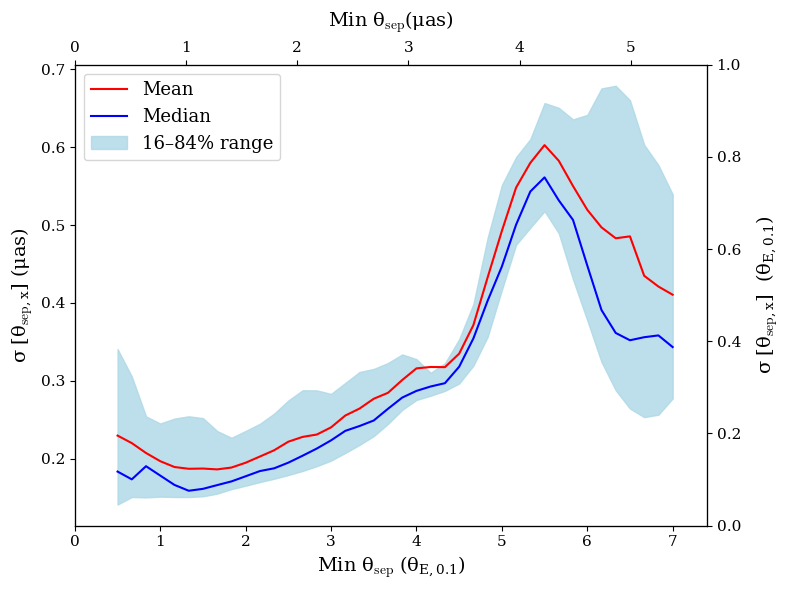

In [64]:
p16 = np.array(np.percentile(uncert_full[:,:,2], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,2], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,2], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ylim=4.1
ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\theta_{\text{sep},x}]$  ($\theta_{E, 0.1}$)',  fontsize=14, labelpad=10)
#ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [\theta_{\text{sep},x}]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [11]:
np.array(uncert_full[:,:,2])

array([[0.3513350140866865, 0.23876174052925844, 0.24570837158776565,
        ..., 0.24757939080203079, 0.15146217115189606,
        0.3378296450596437],
       [0.28138823074786923, 0.33871455693990604, 0.14992293877269983,
        ..., 0.1660410297147982, 0.1514360260818869, 0.216186005570338],
       [0.1518456564276891, 0.18647508797629783, 0.18821557805175881,
        ..., 0.21710607821664127, 0.1610784622398575, 0.1807311225591634],
       ...,
       [0.5076540829691567, 0.5124769982885379, 0.4465311463156148, ...,
        0.7931989478344309, 0.5693215019279525, 0.5074888829028672],
       [0.40730709678917, 0.3318981837851528, 0.328441399189774, ...,
        0.26721876294350094, 0.333380399018444, 0.4023245117139787],
       [0.36638803496117334, 0.2735153853356983, 1.7123339332527152, ...,
        0.9783670547469012, 0.8244023741930838, 0.2506110947035309]],
      shape=(15, 10300), dtype=object)

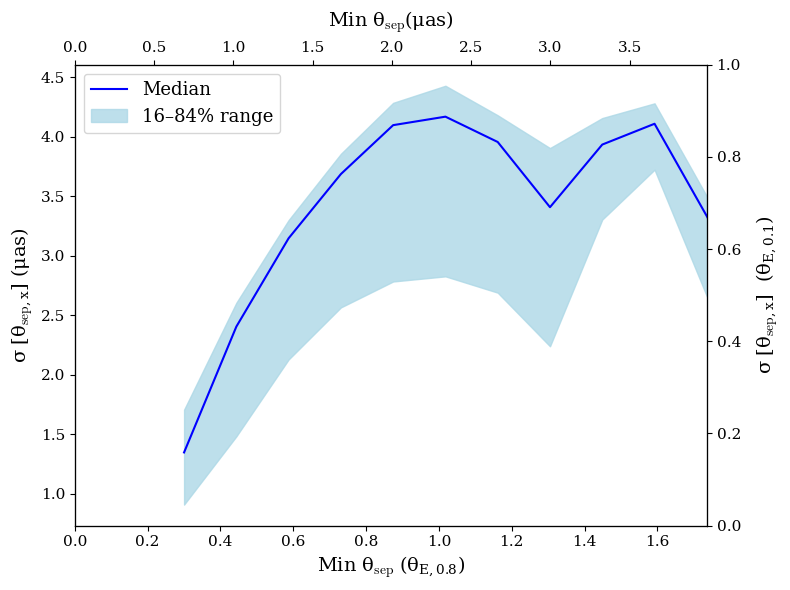

In [15]:
dist_uncert=(np.array(uncert_full[:,:,2])**2+np.array(uncert_full[:,:,3])**2)**.5
p16 = np.array(np.percentile(dist_uncert, 16, axis=1), dtype=float)
p84= np.array(np.percentile(dist_uncert, 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_8, (impact_params/theta_E_8)/np.percentile(dist_uncert, 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, (impact_params/theta_E_8)/p16, (impact_params/theta_E_8)/p84,  alpha=0.8, label='16–84% range', color='lightblue')
ylim=4.1
ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\theta_{\text{sep},x}]$  ($\theta_{E, 0.1}$)',  fontsize=14, labelpad=10)
#ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [\theta_{\text{sep},x}]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

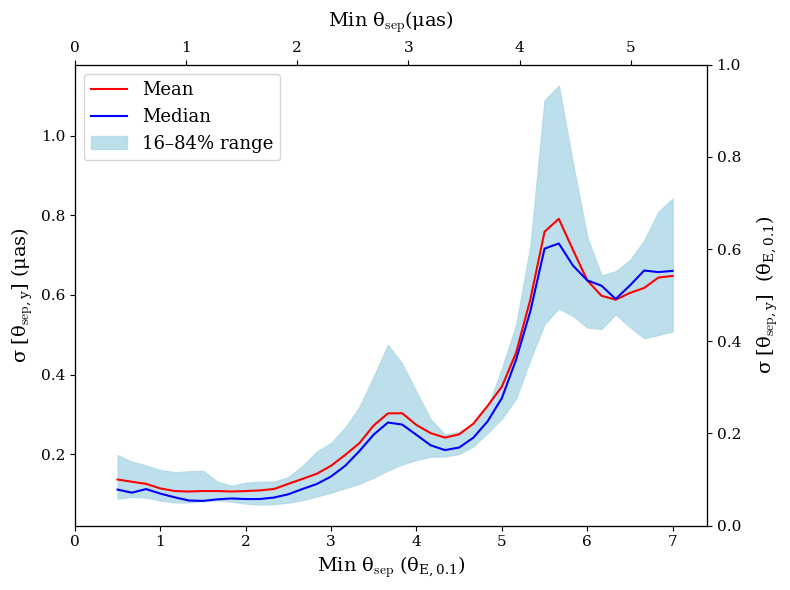

In [65]:
p16 = np.array(np.percentile(uncert_full[:,:,3], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,3], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))
ylim=3.7

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,3], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_right.set_ylabel(r'$\sigma \ [\theta_{\text{sep},y}]$  ($\theta_{E, 0.1}$)',  fontsize=14, labelpad=10)
#ax_right.set_ylim(0,ylim/(rad_to_arcsec*theta_E_8[0]))

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [\theta_{\text{sep},y}]$ ($\mu$as)", fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

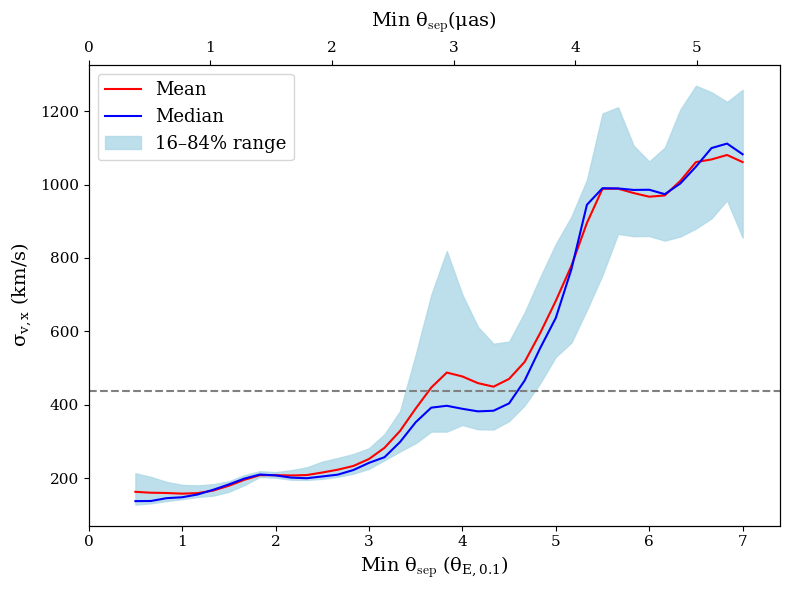

In [66]:
p16 = np.array(np.percentile(uncert_full[:,:,4], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,4], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) #actual here has mean around 400 km/s and std 207.2 km/s
ylim=5.1

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,4], 50, axis=1),color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, x}$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

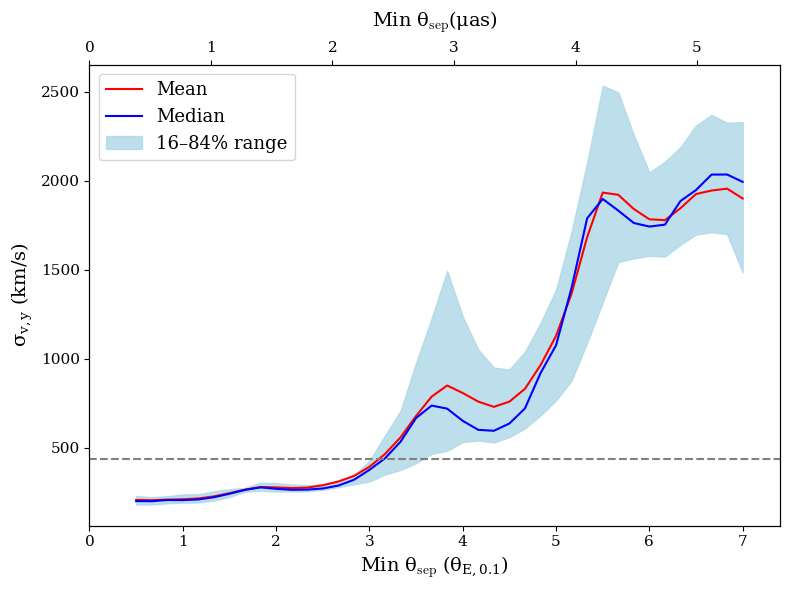

In [67]:
# mean 0 and std 181.4 km/s
p16 = np.array(np.percentile(uncert_full[:,:,5], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,5], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,5], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, y}$ (km/s)", fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

### Probabilities

Now answering the question "will we ever see any such lens trajectories?"

In [41]:
def expected_time_to_encounter(stellar_density, v_bulk, v_bulk_err, vel_disp, vel_disp_err, L_min, 
                               B_matrix, redshift, lens_dist, n_samples=100000,seed=None, L_max=None, cutoff=4.5*theta_E_8[0]):
    """
    Not specific to a 0.1 solar mass star, this is general
    get expected time for a star to come within L_min of the quasar, given surface density near the quasar and velocity distributions
    inputs:
        stellar_density: surface number density of stars (in 1/rad^2)
        v_bulk: vel of the galaxy in km/s, assuemd to be entirely in the x-direction
        vel_disp: km/s
        L_min: minimum impact distance, ie how close we require our star to be to the quasar
        n_samples: number of samples to estimate the avg transverse speed
    returns:
        t_exp_yr: time until the next close encounter in years
        encounter_rate: inverse of t_exp_yr, num encounters/yr
    """
    
    rng = np.random.default_rng(seed)
    seconds_year=31536000
    km_to_cm = 1e5
    
    # angular => distances in cm
    L_min_phys = L_min * D_l
    if L_max is not None:
        L_max_phys = L_max * D_l
    else:
        L_max_phys = None

    vel_angle = rng.uniform(0, 2*np.pi, size=n_samples)

    # sample bulk velocity and dispersion for each star
    # assume bulk along x, plus Gaussian scatter
    v_bulk_samples = rng.normal(loc=v_bulk, scale=v_bulk_err, size=n_samples)
    vel_disp_samples = rng.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2), size=n_samples)

    # total velocity components
    v_x_kms = v_bulk_samples + vel_disp_samples * np.cos(vel_angle)
    v_y_kms = vel_disp_samples * np.sin(vel_angle)

    # convert to cm/s
    v_rest = np.stack([v_x_kms, v_y_kms], axis=-1) * km_to_cm  # shape (n_samples, 2)

    # apply lensing/angular conversion
    v_ang = np.array([get_velocities(v, B_matrix, redshift, lens_dist) for v in v_rest])
    v_phys = v_ang * lens_dist

    # transverse speed per sample
    v_perp = np.linalg.norm(v_phys, axis=1)  # shape (n_samples,)
    mean_ang_v=(np.mean(np.linalg.norm(v_ang, axis=1)*365.25*24*3600)) #rad/year
    
    # effective width of encounter band
    if L_max_phys is None:
        delta_L = L_min_phys  # encounter within radius L_min
    else:
        delta_L = (L_max_phys - L_min_phys)  # encounter between L_min and L_max

    # per-star area swept per second 
    rate_per_star = 2 * delta_L * v_perp
    encounter_rate = stellar_density * np.mean(rate_per_star)
    t_expected = 1.0 / encounter_rate
    t_exp_yr=t_expected/seconds_year
    char_time = 2 * np.sqrt(cutoff**2 - L_min**2) / mean_ang_v # path length inside a circle of radius cutoff is sqrt(cutoff**2-L_min**2)

    
    return t_exp_yr, 1/t_exp_yr, char_time


In [42]:
# kappa values are here: https://arxiv.org/pdf/2303.11987
kappa_star= 0.04 #dimensionless, we want this over kappa_crit
kappa_crit=(c**2/(4*np.pi*G))*(D_s/(D_l*D_ls)) # g/cm^2
Sigma_star=kappa_star*kappa_crit
avg_star_mass=.5*u.solMass.to(u.g) # ~typical mass of a star
n=(Sigma_star/avg_star_mass) #stars/cm^2
expected_time_to_encounter(n, bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, 0.3*theta_E_8[0], B_matrix, z_l, D_l, L_max=None)

(np.float64(446.8718056451532),
 np.float64(0.002237778233863491),
 np.float64(49.30219908716143))

In [43]:
# calculate it all for a few example impact parameters
impact_params_time=np.array([0.3, 0.730769, 1.161538, 1.592308, 2.023077, 
                             2.453846, 2.884615, 3.315385, 3.746154, 4.176923])
# years between events
years_bet=[]

#how long such an event lasts
years_last=[]
for i in impact_params_time:
    exp, _, char = expected_time_to_encounter(n, bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, i*theta_E_8[0], B_matrix, z_l, D_l, L_max=None)
    years_bet.append(exp)
    years_last.append(char)

In [45]:
df=pd.DataFrame((np.array((impact_params_time, years_bet, years_last)).T))
df

,0,1,2
0,0.300000,446.262512,49.234977
1,0.730769,182.875178,48.602750
2,1.161538,115.158336,47.630600
3,1.592308,84.093770,46.160748
4,2.023077,66.219400,44.105929
5,2.453846,54.553436,41.358799
6,2.884615,46.318538,37.797360
7,3.315385,40.304517,33.301846
8,3.746154,35.725084,27.330196
9,4.176923,32.138345,18.409106
